In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def softmax(x):
    x = 1/x
    x_exp = np.exp(x)
    sm = [x_exp[i]/np.sum(x_exp) for i in range(len(x))]
    return sm

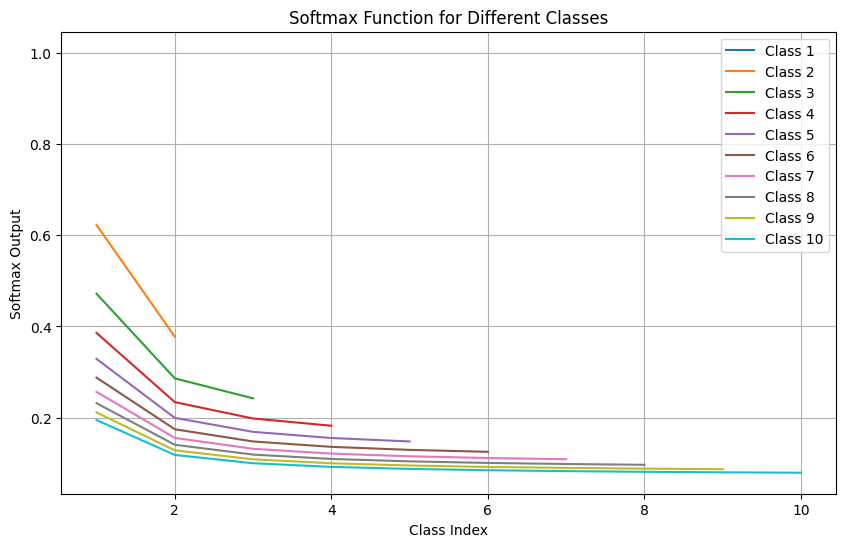

In [3]:
num_class = 10
plt.figure(figsize=(10, 6))
for i in range(1, num_class+1):
    x = np.arange(1, i+1)
    y = softmax(x)
    plt.plot(x, y, label=f'Class {i}')
plt.title('Softmax Function for Different Classes')
plt.xlabel('Class Index')
plt.ylabel('Softmax Output')
plt.legend()
plt.grid()
plt.show()



# Utiles

In [82]:
def extract_states(scenario):
    return [scenario[i] for i in range(0,len(scenario),2)]

def extract_events(scenario):
    return [scenario[i] for i in range(1,len(scenario),2)]


In [83]:
def compute_perplexity(scenario,expert):
    events = extract_events(scenario)
    states = extract_states(scenario)
    N= len(events)
    list_proba = [expert[states[i]][events[i]] for i in range(len(events))]
    perplexite = np.exp(-1/N * np.sum([np.log(list_proba)]))
    return perplexite

In [84]:
def levenshtein_distance(s1, s2):
    n,m= len(s1), len(s2)
    dp = np.zeros((n+1,m+1))
    for i in range(n+1):
        for j in range(m+1):
            if i==0:
                dp[i][j] = j
            elif j==0:
                dp[i][j] = i
            elif s1[i-1] == s2[j-1]: 
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = 1 + min(dp[i-1][j]+1, dp[i][j-1], dp[i-1][j-1]) # insertion, deletion, substitution
    return dp[n][m]

In [85]:
def coût(scenario,scenario_cf, scenarios, expert, lambda1 = 1, lambda2= 1):
    perplexite = compute_perplexity(scenarios[scenario_cf],expert)
    distance = levenshtein_distance(extract_states(scenarios[scenario]), extract_states(scenarios[scenario_cf]))
    cout = lambda1*perplexite + lambda2*distance
    return (cout, perplexite, distance)

In [100]:
def critere_selection(scenario,scenario_cf,scenarios,expert, val_cout = None):
    cout,_,_ = coût(scenario,scenario_cf,scenarios,expert)
    critere_cout = cout <= val_cout if val_cout is not None else True
    states = extract_states(scenarios[scenario])
    states_cf = extract_states(scenarios[scenario_cf])
    valid = False
    if states[-1]!= states_cf[-1]:
        valid = True
    return critere_cout and valid
    

In [112]:
def print_res(scenarios, expert):
    print(f"Obs: states: {extract_states(scenarios['obs'])},events: {extract_events(scenarios['obs'])}")
    res = { scenario: coût("obs",scenario,scenarios,expert) for scenario in scenarios.keys()}
    res = dict(sorted(res.items(), key=lambda item:item[1][0]))
    for scenario in res.keys():
        if scenario != "obs":
            print(f"Cout pour {scenario}:  {res[scenario][0]:.2f}, (perplexité: {res[scenario][1]:.2f}, distance: {res[scenario][2]}), (states: {extract_states(scenarios[scenario])}, events: {extract_events(scenarios[scenario])})")
    print("CF valides: ")
    for scenario in scenarios.keys():
        if scenario != "obs" and critere_selection("obs",scenario,scenarios,expert):
            print(f"Coût pour {scenario}:  {res[scenario][0]:.2f}, (perplexité: {res[scenario][1]:.2f}, distance: {res[scenario][2]}), (states: {extract_states(scenarios[scenario])}, events: {extract_events(scenarios[scenario])})")

# Exemple Poison

In [101]:
tau = {
    ("VO","boire","vivant"),
    ("VO","emp","VE"),
    ("VO","vider","VV"),
    ("VE","vider","VV"),
    ("VE","boire","mort"),
    ("VE","antidote","VA"),
    ("VA","boire","vivant"),
    ("VV","nothing","mort"),
    ("vivant","nothing","vivant"),
    ("mort","nothing","mort")
}

In [102]:
expert = {
    "VO": {"boire":0.7,"vider":0.2,"emp":0.1},
    "VE": {"antidote":0.7,"boire":0.15,"vider":0.15},
    "VV": {"nothing":1},
    "VA": {"boire":1},
    "mort" : {"nothing":1},
    "vivant":{"nothing":1}
}

In [103]:
scenarios = {
    "obs": ["VO","emp","VE","boire","mort"],
    "CF1": ["VO","boire","vivant"],
    "CF2": ["VO","vider","VV","nothing","mort"],
    "CF3": ["VO","emp","VE","vider","VV","nothing","mort"],
    "CF4": ["VO", "emp","VE","antidote","VA","boire","vivant"]
}

In [104]:
expert_class = {
    "VO": {"boire":.47,"vider":.29,"emp":.24},
    "VE": {"antidote":.46,"boire":.27,"vider":.27},
    "VV": {"nothing":1},
    "VA": {"boire":1},
    "mort" : {"nothing":1},
    "vivant":{"nothing":1}
}

In [105]:
res = { scenario: compute_perplexity(scenarios[scenario],expert) for scenario in scenarios.keys()}
res = dict(sorted(res.items(), key=lambda item: item[1]))
for scenario in res.keys():
    print(f"Perplexité {scenario}: {res[scenario]}, (states: {extract_states(scenarios[scenario])}, events: {extract_events(scenarios[scenario])})")

Perplexité CF1: 1.4285714285714286, (states: ['VO', 'vivant'], events: ['boire'])
Perplexité CF2: 2.23606797749979, (states: ['VO', 'VV', 'mort'], events: ['vider', 'nothing'])
Perplexité CF4: 2.426427503202586, (states: ['VO', 'VE', 'VA', 'vivant'], events: ['emp', 'antidote', 'boire'])
Perplexité CF3: 4.054801330382266, (states: ['VO', 'VE', 'VV', 'mort'], events: ['emp', 'vider', 'nothing'])
Perplexité obs: 8.164965809277257, (states: ['VO', 'VE', 'mort'], events: ['emp', 'boire'])


In [106]:
res = { scenario: compute_perplexity(scenarios[scenario],expert_class) for scenario in scenarios.keys()}
res = dict(sorted(res.items(), key=lambda item: item[1]))
for scenario in res.keys():
    print(f"Perplexité {scenario}: {res[scenario]}, (states: {extract_states(scenarios[scenario])}, events: {extract_events(scenarios[scenario])})")

Perplexité CF2: 1.8569533817705188, (states: ['VO', 'VV', 'mort'], events: ['vider', 'nothing'])
Perplexité CF4: 2.0845403633445807, (states: ['VO', 'VE', 'VA', 'vivant'], events: ['emp', 'antidote', 'boire'])
Perplexité CF1: 2.127659574468085, (states: ['VO', 'vivant'], events: ['boire'])
Perplexité CF3: 2.489669303642869, (states: ['VO', 'VE', 'VV', 'mort'], events: ['emp', 'vider', 'nothing'])
Perplexité obs: 3.9283710065919313, (states: ['VO', 'VE', 'mort'], events: ['emp', 'boire'])


In [107]:
for scenario in scenarios.keys():
    print(f"Distance de Levenshtein entre obs et {scenario} : {levenshtein_distance(extract_states(scenarios['obs']), extract_states(scenarios[scenario]))}")

Distance de Levenshtein entre obs et obs : 0.0
Distance de Levenshtein entre obs et CF1 : 3.0
Distance de Levenshtein entre obs et CF2 : 1.0
Distance de Levenshtein entre obs et CF3 : 1.0
Distance de Levenshtein entre obs et CF4 : 2.0


In [108]:
print(f"Obs: states: {extract_states(scenarios['obs'])},events: {extract_events(scenarios['obs'])}")
res = { scenario: coût("obs",scenario,scenarios,expert) for scenario in scenarios.keys()}
res = dict(sorted(res.items(), key=lambda item:item[1][0]))
for scenario in res.keys():
    if scenario != "obs":
        print(f"Cout pour {scenario}:  {res[scenario][0]:.2f}, (perplexité: {res[scenario][1]:.2f}, distance: {res[scenario][2]}), (states: {extract_states(scenarios[scenario])}, events: {extract_events(scenarios[scenario])})")

Obs: states: ['VO', 'VE', 'mort'],events: ['emp', 'boire']
Cout pour CF2:  3.24, (perplexité: 2.24, distance: 1.0), (states: ['VO', 'VV', 'mort'], events: ['vider', 'nothing'])
Cout pour CF4:  4.43, (perplexité: 2.43, distance: 2.0), (states: ['VO', 'VE', 'VA', 'vivant'], events: ['emp', 'antidote', 'boire'])
Cout pour CF1:  4.43, (perplexité: 1.43, distance: 3.0), (states: ['VO', 'vivant'], events: ['boire'])
Cout pour CF3:  5.05, (perplexité: 4.05, distance: 1.0), (states: ['VO', 'VE', 'VV', 'mort'], events: ['emp', 'vider', 'nothing'])


In [111]:
print("CF valides: ")
for scenario in scenarios.keys():
    if scenario != "obs" and critere_selection("obs",scenario,scenarios,expert):
        print(f"Coût pour {scenario}:  {res[scenario][0]:.2f}, (perplexité: {res[scenario][1]:.2f}, distance: {res[scenario][2]}), (states: {extract_states(scenarios[scenario])}, events: {extract_events(scenarios[scenario])})")

CF valides: 
Coût pour CF1:  4.43, (perplexité: 1.43, distance: 3.0), (states: ['VO', 'vivant'], events: ['boire'])
Coût pour CF4:  4.43, (perplexité: 2.43, distance: 2.0), (states: ['VO', 'VE', 'VA', 'vivant'], events: ['emp', 'antidote', 'boire'])


In [113]:
print_res(scenarios, expert)

Obs: states: ['VO', 'VE', 'mort'],events: ['emp', 'boire']
Cout pour CF2:  3.24, (perplexité: 2.24, distance: 1.0), (states: ['VO', 'VV', 'mort'], events: ['vider', 'nothing'])
Cout pour CF4:  4.43, (perplexité: 2.43, distance: 2.0), (states: ['VO', 'VE', 'VA', 'vivant'], events: ['emp', 'antidote', 'boire'])
Cout pour CF1:  4.43, (perplexité: 1.43, distance: 3.0), (states: ['VO', 'vivant'], events: ['boire'])
Cout pour CF3:  5.05, (perplexité: 4.05, distance: 1.0), (states: ['VO', 'VE', 'VV', 'mort'], events: ['emp', 'vider', 'nothing'])
CF valides: 
Coût pour CF1:  4.43, (perplexité: 1.43, distance: 3.0), (states: ['VO', 'vivant'], events: ['boire'])
Coût pour CF4:  4.43, (perplexité: 2.43, distance: 2.0), (states: ['VO', 'VE', 'VA', 'vivant'], events: ['emp', 'antidote', 'boire'])


# Exemple Jardinier

## Case 1

In [115]:
tau = {
    ("S0","JW","S1"),
    ("S0","nothing","S1"),
    ("S1","nothing","S1"),
}

expert = {
    "S0": {"JW":0.9,"nothing":0.1},
    "S1": {"nothing":1}
}

scenarios = {
    "obs": ["S0","nothing","S1"],
    "CF1": ["S0","JW","S0"],
    "CF2": ["S1","nothing","S1"]
}

In [116]:
print_res(scenarios,expert)

Obs: states: ['S0', 'S1'],events: ['nothing']
Cout pour CF2:  2.00, (perplexité: 1.00, distance: 1.0), (states: ['S1', 'S1'], events: ['nothing'])
Cout pour CF1:  2.11, (perplexité: 1.11, distance: 1.0), (states: ['S0', 'S0'], events: ['JW'])
CF valides: 
Coût pour CF1:  2.11, (perplexité: 1.11, distance: 1.0), (states: ['S0', 'S0'], events: ['JW'])


perplexite + faible pour CF2 car en soit on a rien fait du surprenant en partant de S1 parce qu'on avait aucun choix

## Case 2

In [118]:
tau = {
    ("S0","JW","S1"),
    ("S0","SW","S1"),
    ("S0","nothing","S2"),
    
    ("S1","nothing","S1"),
    ("S2","nothing","S2"),
}

expert = {
    "S0": {"JW": 0.7,"nothing":0.2,"SW":0.1},
    "S1": {"nothing":1},
    "S2": {"nothing":1}
}

scenarios = {
    "obs" : ["S0","nothing","S2"],
    "CF1" : ["S0", "JW", "S1"],
    "CF2" : ["S0", "SW", "S1"],
}

In [119]:
print_res(scenarios, expert)

Obs: states: ['S0', 'S2'],events: ['nothing']
Cout pour CF1:  2.43, (perplexité: 1.43, distance: 1.0), (states: ['S0', 'S1'], events: ['JW'])
Cout pour CF2:  11.00, (perplexité: 10.00, distance: 1.0), (states: ['S0', 'S1'], events: ['SW'])
CF valides: 
Coût pour CF1:  2.43, (perplexité: 1.43, distance: 1.0), (states: ['S0', 'S1'], events: ['JW'])
Coût pour CF2:  11.00, (perplexité: 10.00, distance: 1.0), (states: ['S0', 'S1'], events: ['SW'])


# Toy exemple

In [128]:
tau = {
    ("S0","a0","S2"),
    ("S0","b0","S1"),
    
    ("S1","a1","S2"),
    
    ("S2","a2","S3"),
    ("S2","b2","S4"),
    ("S2","c2","S5"),
    ("S2","d2","S6"),
    
    ("S3","a3","S4"),
    ("S3","b3","S8"),
    
    ("S4","a4","S8"),
    ("S5","a5","S7"),
    ("S6","a6","S7"),
    
    ("S7","a7","S8"),
    
    ("S8","nothing","S8")
    
}

expert = {
    "S0":{"a0": 0.1,"b0": 0.9},
    "S1":{"a1": 1},
    "S2":{"a2": 0.25,"b2": 0.25,"c2": 0.25,"d2": 0.25},
    "S3":{"a3": 0.1,"b3":0.9},
    "S4":{"a4": 1},
    "S5":{"a5": 1},
    "S6":{"a6": 1},
    "S7":{"a7": 1},
    "S8":{"nothing":1},
}

scenarios = {
    "obs": ["S0","b0","S1","a1","S2","d2","S6","a6","S7","a7","S8"],
    "CF1": ["S0","b0","S1","a1","S2","c2","S5","a5","S7","a7","S8"],
    "CF2": ["S0","b0","S1","a1","S2","c2","S6","a6","S7","a7","S8"],
    "CF4": ["S0","b0","S1","a1","S2","b2","S4","a4","S8"],
    "CF5": ["S0","b0","S1","a1","S2","b2","S3","b3","S8"],
    "CF6": ["S0","b0","S1","a1","S2","b2","S3","a3","S4","a4","S8"],
    "CF7": ["S0","a0","S2","c2","S5","a5","S7","a7","S8"],
    "CF8": ["S0","a0","S2","c2","S6","a6","S7","a7","S8"],
    "CF9": ["S0","a0","S2","b2","S4","a4","S8"],
    "CF10": ["S0","a0","S2","b2","S3","b3","S8"],
    "CF11": ["S0","a0","S2","b2","S3","a3","S4","a4","S8"],
    
}

print_res(scenarios, expert)

Obs: states: ['S0', 'S1', 'S2', 'S6', 'S7', 'S8'],events: ['b0', 'a1', 'd2', 'a6', 'a7']
Cout pour CF2:  1.35, (perplexité: 1.35, distance: 0.0), (states: ['S0', 'S1', 'S2', 'S6', 'S7', 'S8'], events: ['b0', 'a1', 'c2', 'a6', 'a7'])
Cout pour CF1:  2.35, (perplexité: 1.35, distance: 1.0), (states: ['S0', 'S1', 'S2', 'S5', 'S7', 'S8'], events: ['b0', 'a1', 'c2', 'a5', 'a7'])
Cout pour CF6:  4.14, (perplexité: 2.14, distance: 2.0), (states: ['S0', 'S1', 'S2', 'S3', 'S4', 'S8'], events: ['b0', 'a1', 'b2', 'a3', 'a4'])
Cout pour CF4:  4.45, (perplexité: 1.45, distance: 3.0), (states: ['S0', 'S1', 'S2', 'S4', 'S8'], events: ['b0', 'a1', 'b2', 'a4'])
Cout pour CF5:  4.49, (perplexité: 1.49, distance: 3.0), (states: ['S0', 'S1', 'S2', 'S3', 'S8'], events: ['b0', 'a1', 'b2', 'b3'])
Cout pour CF8:  4.51, (perplexité: 2.51, distance: 2.0), (states: ['S0', 'S2', 'S6', 'S7', 'S8'], events: ['a0', 'c2', 'a6', 'a7'])
Cout pour CF7:  5.51, (perplexité: 2.51, distance: 3.0), (states: ['S0', 'S2', 'S5'